It seems like the cross-correlation is significantly affected by flexibility away from native structure.

Let's see how selecting frames with RNA configuration lying closer to the reference affects the result.

In [9]:
import itertools
import numpy as np
import MDAnalysis as mda
from MDAnalysis.transformations import fit_rot_trans
from MDAnalysis.analysis import rms

from dask import delayed, compute
from dask.distributed import Client

from tqdm import tqdm


from scipy.stats import linregress


from mg_sampling import PROJECT_DIR
from mg_sampling.tools import read_plumed
from mg_sampling.density.align import (
    TransformationFromFunction,
    check_alignable,
    reorder_residue_atoms,
    standardize_names,
    unwrap_sequential,
    wrap_around_atomgroup,
)
from mg_sampling.density.forward_density import atomgroup_to_map
from mg_sampling.density.grid import Grid, SparseGrid
from mg_sampling.density.utils import indices_to_mask, voxels_around
from mg_sampling.tools import edges_to_range, bayesian_bootstrap

import pandas as pd
import seaborn as sns

from scipy.constants import R
RT = 300 * R / 1000  # kJ/mol

### Compute RMSD to reference structures

In [2]:
n_workers = 12

# Iterate
pdbids = ['9CBU', '7EZ0']
methods = ["plain_md"]
systems = ["7ez0"]
forcefields = ["nMg_tip3p", "nMg_tip3p_soft"]
replicates = range(1)
repids = range(8)

def run(pdbid, method, sys, ff, rep, i):

    # Reference structure to align to
    ref_file = PROJECT_DIR / f"structures/{pdbid}_fixed.pdb"
    ref = mda.Universe(ref_file)
    ref_align = reorder_residue_atoms(
        ref.select_atoms("not type H and nucleic and not (resid 22 and name P OP1 OP2)")
    )

    path = PROJECT_DIR / f"{method}/{sys}/{ff}/replicate{rep}/rep{i+rep*8:02d}"

    out_file = path / f'rmsd_{pdbid}.txt'

    if out_file.exists():
        print("Skipping", out_file)
        return
    
    top_file = path / "input.gro"
    traj_file = path / "run.xtc"

    u = mda.Universe(top_file, traj_file)

    standardize_names(u)
    mob_align = reorder_residue_atoms(u.select_atoms("not type H and nucleic"))
    check_alignable(mob_align, ref_align)

    workflow = [
        TransformationFromFunction(unwrap_sequential, mob_align),
    ]
    u.trajectory.add_transformations(*workflow)

    # Compute RMSD
    rmsd = np.array([rms.rmsd(mob_align.positions, ref_align.positions, center=True, superposition=True) for ts in tqdm(u.trajectory)])

    np.savetxt(out_file, rmsd)

    tasks.append(delayed(run))

tasks = []
for pdbid, method, sys, ff, rep, i in itertools.product(pdbids, methods, systems, forcefields, replicates, repids):
    tasks.append(
        delayed(run)(pdbid, method, sys, ff, rep, i)
    )

with Client(threads_per_worker=1, n_workers=n_workers) as client:
    print(f"Computing {len(tasks)} tasks…", flush=True)
    print("Dashboard:", client.dashboard_link)
    compute(*tasks)

Computing 32 tasks…
Dashboard: http://127.0.0.1:8787/status


/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/sit

Skipping /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0/nMg_tip3p/replicate0/rep00/rmsd_7EZ0.txt
Skipping /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0/nMg_tip3p_soft/replicate0/rep06/rmsd_7EZ0.txt
Skipping /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0/nMg_tip3p_soft/replicate0/rep02/rmsd_9CBU.txt
Skipping /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0/nMg_tip3p/replicate0/rep07/rmsd_9CBU.txt
Skipping /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0/nMg_tip3p_soft/replicate0/rep05/rmsd_9CBU.txt
Skipping /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0/nMg_tip3p/replicate0/rep05/rmsd_9CBU.txt
Skipping /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0/nMg_tip3p_soft/replicate0/rep07/rmsd_9CBU.txt
Skipping /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0/nMg_tip3p/replicate0/rep02/rmsd_7EZ0.txt
Skipping /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0/nMg_tip3p/replicate0/rep02/rmsd_9CBU.txt
Skipping /net/sbp/sbpstore2/olanguin/mg_samp

### Method 1: divide around median RMSD

In [ ]:
# Reference *for RMSD selection* (not for alignment)
rmsd_ref = "7EZ0"

device = "cuda"
chunk_size = 8192
n_workers = 8

# Reference CryoEM map (for map geometry)
grid_params = Grid(
    PROJECT_DIR / "density/emd_42499.mrc", file_format="mrc"
).grid_params

# Reference structure to align to
ref_file = PROJECT_DIR / f"structures/9CBU_fixed.pdb"
ref = mda.Universe(ref_file)
ref_align = reorder_residue_atoms(
    ref.select_atoms("not type H and nucleic and not (resid 22 and name P OP1 OP2)")
)
vox_indices = voxels_around(ref_align, 6, grid_params)

# Iterate
methods = ["plain_md"]
systems = ["7ez0"]
forcefields = ["nMg_tip3p", "nMg_tip3p_soft"]
replicates = range(1)
repids = range(8)
out_sels = {'all': "not type H"}

def run(method, sys, ff, rep, i, out):
    path = PROJECT_DIR / f"{method}/{sys}/{ff}/replicate{rep}/rep{i+rep*8:02d}"

    top_file = path / "input.gro"
    traj_file = path / "run.xtc"

    u = mda.Universe(top_file, traj_file)

    standardize_names(u)
    mob_align = reorder_residue_atoms(u.select_atoms("not type H and nucleic"))
    check_alignable(mob_align, ref_align)

    # For efficiently wrapping solvent around
    mob_align_light = mob_align.select_atoms("name P")[::5]

    mob_out = u.select_atoms(out_sels[out])
    mob_out_or_align = mob_out | mob_align
    mob_out_sub = mob_out_or_align.select_atoms(
        "group mob_out and (group mob_align or around 10 group mob_align)",
        mob_align=mob_align,
        mob_out=mob_out,
        updating=True,
    )

    workflow = [
        TransformationFromFunction(unwrap_sequential, mob_align),
        TransformationFromFunction(wrap_around_atomgroup, mob_out_sub, mob_align_light),
        fit_rot_trans(mob_align, ref_align),
    ]
    u.trajectory.add_transformations(*workflow)

    rmsd = np.loadtxt(path / f"rmsd_{rmsd_ref}.txt")

    for rmsd_class in ('high', 'low'):

        outpath = PROJECT_DIR / f"density/{method}_{sys}_{ff}/{out}/{rmsd_class}_rmsd_{rmsd_ref}"
        outpath.mkdir(exist_ok=True, parents=True)
        out_file = outpath / f"replicate{rep}_rep{i:02d}.pkl"

        sel = np.zeros(len(u.trajectory), dtype=bool)

        # Skip first 1/4 = 150 ns
        # Subsample every 12 frames
        # Total frames per map: 4500 ÷ 12 * 8 ~ 3000
        sel[1000:4000:8] = True
        median_rmsd = np.median(rmsd[sel])
        
        frames = sel & (rmsd > median_rmsd) if rmsd_class == 'high' else sel & (rmsd <= median_rmsd)

        print(f"Selected {int(frames.sum())} frames from {len(u.trajectory)}")

        tot_map = 0
        for ts in u.trajectory[frames]:
            out_file_ts = out_file.with_stem(out_file.stem + f"_{ts.frame}")
            map_ = atomgroup_to_map(
                mob_out_sub.atoms,
                shape=grid_params['shape'],
                delta=grid_params['delta'],
                origin=grid_params['origin'],
                vox_indices=vox_indices,
                cutoff=4.0,
                device=device,
                chunk_size=chunk_size,
            )
            tot_map += map_
            if ts.frame % 100 == 0:
                with mda.Writer(out_file_ts.with_suffix(".pdb")) as w:
                    w.write(mob_out_sub.atoms)
                map_.save(out_file_ts.with_suffix(".pkl"))

        tot_map /= len(u.trajectory[frames])

        print("Saving output map:", out_file, flush=True)
        tot_map.save(out_file)

        weight_file = out_file.with_stem(out_file.stem + "_weight").with_suffix(".txt")
        with open(weight_file, "w") as f:
            f.write(f"{frames.sum()}")

tasks = []
for method, sys, ff, rep, i, out in itertools.product(methods, systems, forcefields, replicates, repids, out_sels):
    tasks.append(
        delayed(run)(method, sys, ff, rep, i, out)
    )

with Client(threads_per_worker=1, n_workers=n_workers) as client:
    print(f"Computing {len(tasks)} tasks…", flush=True)
    print("Dashboard:", client.dashboard_link)
    compute(*tasks)


### Method 2: derivative

We would like to estimate how cross correlation $r$ varies as a function of the restraint $κ$ acting on the RMSD $ξ$ to some reference structure.

We do it with finite differences by measuring

$
\frac{\partial r}{\partial κ} \approx \frac{Δr}{Δκ}
$

for small $Δκ$.

We choose $Δκ$ such that it has a significant effect on the fluctuations $σ_ξ$ of the CV $ξ$.

Since
$
U(ξ) = \frac{κ}{2}ξ^2
$

The typical corresponding bias fluctuation is

$
σ_U \approx κ\langle ξ \rangle σ_ξ
$

To be detectable we want a small change in $κ$, $Δκ$ to perturb the energy fluctuations on the order of $k_BT$

$
Δσ_U \approx Δκ \langle ξ \rangle σ_ξ = k_BT
$

Which gives

$
Δκ = \frac{k_BT}{\langle ξ \rangle σ_ξ }
$

The procedure is thus:

- From the trajectory compute $ξ_i$ for each frame
- Compute $\langle ξ \rangle$ and $σ_ξ$ and deduce $Δκ$
- Compute two sets of weights $w^{+}_i$ and $w^{-}_i$ using $ΔU_i = ±\frac{Δκ}{4}ξ_i^2$
- Generate maps and compute $Δr = r^{+} - r^{-}$


In [27]:
# Reference *for RMSD selection* (not for alignment)
rmsd_ref = "7EZ0"

device = "cuda"
chunk_size = 8192
n_workers = 8

# Reference CryoEM map (for map geometry)
grid_params = Grid(
    PROJECT_DIR / "density/emd_42499.mrc", file_format="mrc"
).grid_params

# Reference structure to align to
ref_file = PROJECT_DIR / f"structures/9CBU_fixed.pdb"
ref = mda.Universe(ref_file)
ref_align = reorder_residue_atoms(
    ref.select_atoms("not type H and nucleic and not (resid 22 and name P OP1 OP2)")
)
vox_indices = voxels_around(ref_align, 6, grid_params)

# Iterate
methods = ["plain_md"]
systems = ["7ez0"]
forcefields = ["nMg_tip3p", "nMg_tip3p_soft"]
replicates = range(1)
repids = range(8)
out_sels = {'all': "not type H"}

def run(method, sys, ff, rep, i, out):
    path = PROJECT_DIR / f"{method}/{sys}/{ff}/replicate{rep}/rep{i+rep*8:02d}"

    top_file = path / "input.gro"
    traj_file = path / "run.xtc"

    u = mda.Universe(top_file, traj_file)

    standardize_names(u)
    mob_align = reorder_residue_atoms(u.select_atoms("not type H and nucleic"))
    check_alignable(mob_align, ref_align)

    # For efficiently wrapping solvent around
    mob_align_light = mob_align.select_atoms("name P")[::5]

    mob_out = u.select_atoms(out_sels[out])
    mob_out_or_align = mob_out | mob_align
    mob_out_sub = mob_out_or_align.select_atoms(
        "group mob_out and (group mob_align or around 10 group mob_align)",
        mob_align=mob_align,
        mob_out=mob_out,
        updating=True,
    )

    workflow = [
        TransformationFromFunction(unwrap_sequential, mob_align),
        TransformationFromFunction(wrap_around_atomgroup, mob_out_sub, mob_align_light),
        fit_rot_trans(mob_align, ref_align),
    ]
    u.trajectory.add_transformations(*workflow)

    rmsd = np.loadtxt(path / f"rmsd_{rmsd_ref}.txt")

    for reweighting in ("plus", "minus"):

        outpath = PROJECT_DIR / f"density/{method}_{sys}_{ff}/{out}/rmsd_{rmsd_ref}_kappa_{reweighting}"
        outpath.mkdir(exist_ok=True, parents=True)
        out_file = outpath / f"replicate{rep}_rep{i:02d}.pkl"

        sel = np.zeros(len(u.trajectory), dtype=bool)

        # Skip first 1/4 = 150 ns
        # Subsample every 12 frames
        # Total frames per map: 4500 ÷ 12 * 8 ~ 3000
        sel[1000:4000:8] = True
        avg_rmsd = np.mean(rmsd[sel])
        std_rmsd = np.std(rmsd[sel])
        Δκ = RT / (avg_rmsd * std_rmsd)
        sign = -1 if reweighting == "plus" else -1
        Δu = sign * Δκ * rmsd[sel]**2 / 4
        weights = np.exp(- Δu / RT)
        weights /= weights.sum()
        
        frames = sel

        print(f"Selected {int(frames.sum())} frames from {len(u.trajectory)}")

        tot_map = 0
        for w, ts in zip(weights, u.trajectory[frames]):
            out_file_ts = out_file.with_stem(out_file.stem + f"_{ts.frame}")
            map_ = atomgroup_to_map(
                mob_out_sub.atoms,
                shape=grid_params['shape'],
                delta=grid_params['delta'],
                origin=grid_params['origin'],
                vox_indices=vox_indices,
                cutoff=4.0,
                device=device,
                chunk_size=chunk_size,
            )
            tot_map += w * map_

        print("Saving output map:", out_file, flush=True)
        tot_map.save(out_file)

        weight_file = out_file.with_stem(out_file.stem + "_weight").with_suffix(".txt")
        with open(weight_file, "w") as f:
            f.write(f"{frames.sum()}")

tasks = []
for method, sys, ff, rep, i, out in itertools.product(methods, systems, forcefields, replicates, repids, out_sels):
    tasks.append(
        delayed(run)(method, sys, ff, rep, i, out)
    )

with Client(threads_per_worker=1, n_workers=n_workers) as client:
    print(f"Computing {len(tasks)} tasks…", flush=True)
    print("Dashboard:", client.dashboard_link)
    compute(*tasks)


Computing 16 tasks…
Dashboard: http://127.0.0.1:8787/status
Selected 375 frames from 6001
Selected 375 frames from 6001
Selected 375 frames from 6001
Selected 375 frames from 6001
Selected 375 frames from 6001
Selected 375 frames from 6001
Selected 375 frames from 6001
Selected 375 frames from 6001
Saving output map: /net/sbp/sbpstore2/olanguin/mg_sampling/density/plain_md_7ez0_nMg_tip3p_soft/all/rmsd_7EZ0_kappa_plus/replicate0_rep04.pkl
Selected 375 frames from 6001
Saving output map: /net/sbp/sbpstore2/olanguin/mg_sampling/density/plain_md_7ez0_nMg_tip3p_soft/all/rmsd_7EZ0_kappa_plus/replicate0_rep03.pkl
Selected 375 frames from 6001
Saving output map: /net/sbp/sbpstore2/olanguin/mg_sampling/density/plain_md_7ez0_nMg_tip3p_soft/all/rmsd_7EZ0_kappa_plus/replicate0_rep07.pkl
Selected 375 frames from 6001
Saving output map: /net/sbp/sbpstore2/olanguin/mg_sampling/density/plain_md_7ez0_nMg_tip3p_soft/all/rmsd_7EZ0_kappa_plus/replicate0_rep02.pkl
Selected 375 frames from 6001
Saving outpu

2026-01-26 15:26:38,796 - distributed.worker - ERROR - Failed to communicate with scheduler during heartbeat.
Traceback (most recent call last):
  File "/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/distributed/comm/tcp.py", line 226, in read
    frames_nosplit_nbytes_bin = await stream.read_bytes(fmt_size)
                                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tornado.iostream.StreamClosedError: Stream is closed

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/distributed/worker.py", line 1273, in heartbeat
    response = await retry_operation(
               ^^^^^^^^^^^^^^^^^^^^^^
  File "/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/distributed/utils_comm.py", line 416, in retry_operation
    return await retry(
           ^^^^^^^^^^^^
  File "/net/sbp/sbpstore2/olanguin/mg_sam

TimeoutError: 

### Evaluation

In [2]:
ref_map = 0.5 * (Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc") + Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc"))
rna = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb").select_atoms("nucleic and not type H and not (resid 22 and name P OP1 OP2)")
masks = {
    'RNA-Shell': indices_to_mask(voxels_around(rna, 6, ref_map.grid_params), ref_map.grid_params),
    'RNA': indices_to_mask(voxels_around(rna, 1.8, ref_map.grid_params), ref_map.grid_params),
    'Phosphates': indices_to_mask(voxels_around(rna.select_atoms('name P'), 6, ref_map.grid_params), ref_map.grid_params)
}

masks['Shell'] = masks['RNA-Shell'] & ~masks['RNA']
masks['Phosphates-Shell'] = masks['Phosphates'] & ~masks['RNA']

path = PROJECT_DIR / "density"

data = []
for filename in path.glob("plain_md_7ez0_nMg_tip3p*/all/*_rmsd*/replicate?_rep??.pkl"):
    weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
    if weight_file.exists():
        with open(weight_file, "r") as f:
            weight = float(f.read())
    else:
        weight = 1

    map_ = SparseGrid.load(filename)
    map_ = map_.to_dense().apply_tempfactor(30)

    data.append(
        dict(
            sim=filename.parent.parent.parent.name,
            rmsd_class=filename.parent.name,
            block=filename.stem,
            filename=str(filename),
            map=map_,
            weight=weight,
        )
    )

for filename in path.glob("plain_md_7ez0_nMg_tip3p*/all/replicate?_rep??.pkl"):
    weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
    if weight_file.exists():
        with open(weight_file, "r") as f:
            weight = float(f.read())
    else:
        weight = 1

    map_ = SparseGrid.load(filename)
    map_ = map_.to_dense().apply_tempfactor(30)

    data.append(
        dict(
            sim=filename.parent.parent.name,
            rmsd_class="all",
            block=filename.stem,
            filename=str(filename),
            map=map_,
            weight=weight,
        )
    )

gen_maps = pd.DataFrame(data)

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


In [3]:
gen_maps["weight"] /= gen_maps.groupby(["sim", "rmsd_class"])["weight"].transform("sum")

In [4]:
results = []

for k, mask in masks.items():
    for (sim, rmsd_class), group in tqdm(gen_maps.groupby(["sim", "rmsd_class"])[["map", "weight"]]):
        ref_data = ref_map.grid[mask]
        def statistic(maps, weights=None):
            return linregress(
                np.average(maps, weights=weights),
                ref_data,
            ).rvalue
        mapsA = group["map"].apply(lambda x: x.grid[mask]).to_numpy()
        weightsA = group["weight"].to_numpy()
        mapA = np.average(mapsA, weights=weightsA, axis=0)
        cc = linregress(
            mapA,
            ref_data,
        ).rvalue

        cc_low, cc_high = bayesian_bootstrap(
            mapsA,
            statistic,
            weights=weightsA,
            n_resamples=100,
        ).confidence_interval

        results.append(
            {
                "sim": sim,
                "rmsd_class": rmsd_class,
                "mask": k,
                "cc": cc,
                "cc_low": cc_low,
                "cc_high": cc_high,
            }
        )

100%|██████████| 10/10 [00:05<00:00,  1.90it/s]


In [5]:
pd.DataFrame(results).sort_values(["mask", "cc"]).style.background_gradient(axis=None).format(precision=3)

,sim,rmsd_class,mask,cc,cc_low,cc_high
26,plain_md_7ez0_nMg_tip3p_soft,high_rmsd,Phosphates,0.524,0.473,0.541
27,plain_md_7ez0_nMg_tip3p_soft,high_rmsd_7EZ0,Phosphates,0.525,0.484,0.538
25,plain_md_7ez0_nMg_tip3p_soft,all,Phosphates,0.546,0.494,0.560
29,plain_md_7ez0_nMg_tip3p_soft,low_rmsd_7EZ0,Phosphates,0.563,0.511,0.575
28,plain_md_7ez0_nMg_tip3p_soft,low_rmsd,Phosphates,0.563,0.522,0.575
21,plain_md_7ez0_nMg_tip3p,high_rmsd,Phosphates,0.694,0.689,0.694
24,plain_md_7ez0_nMg_tip3p,low_rmsd_7EZ0,Phosphates,0.697,0.693,0.698
20,plain_md_7ez0_nMg_tip3p,all,Phosphates,0.698,0.694,0.698
22,plain_md_7ez0_nMg_tip3p,high_rmsd_7EZ0,Phosphates,0.698,0.694,0.699
23,plain_md_7ez0_nMg_tip3p,low_rmsd,Phosphates,0.701,0.696,0.702


/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/seaborn/axisgrid.py:854: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0.

  func(*plot_args, **plot_kwargs)
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/seaborn/axisgrid.py:854: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0.

  func(*plot_args, **plot_kwargs)
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/seaborn/axisgrid.py:854: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0.

  func(*plot_args, **plot_kwargs)
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/seaborn/axisgrid.py:854: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0.

  func(*plot_args, **plot_kwargs)
/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/seaborn/axisgrid.py:854: UserWarning: 

The `join` parame

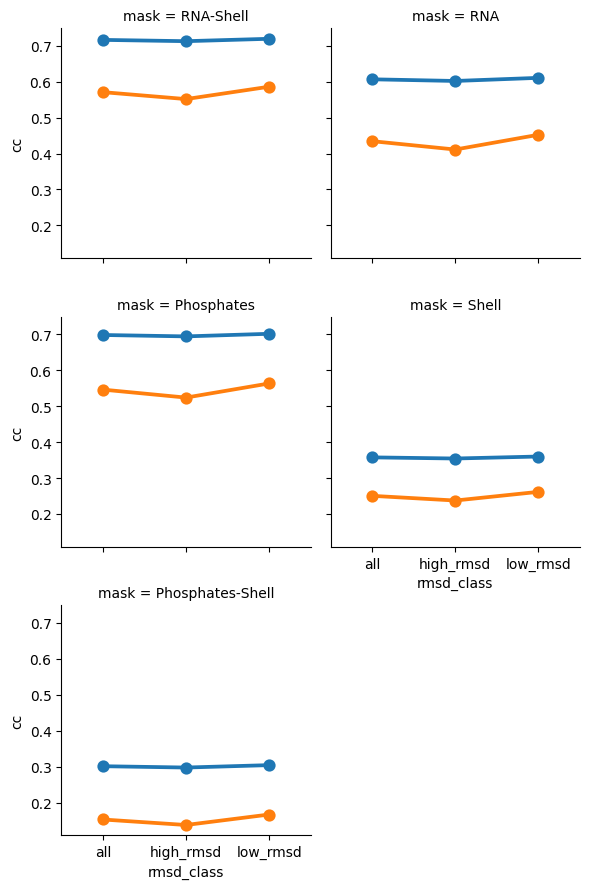

In [11]:
g = sns.FacetGrid(pd.DataFrame(results), col='mask', col_wrap=2, hue='sim')
g.map_dataframe(
    sns.pointplot,
    x = 'rmsd_class',
    y = 'cc',
    join = 'false',
)